# PPKS 01:  Generiranje i operacije nad signalima u Pythonu 

## Signali

Signali opisuju promjenu neke fizičke vrijednosti u vremenu i/ili prostoru.

Na primjer, promjena visine tla u nekoj točki je signal u vremenu, a promjena intenziteta piksela nekog retka u slici je signal u prostoru. Primjer signala koji se mijenja u vremenu i prostoru je redak jednog okvira (eng. frame) u videu. 
Električni signali predstavljaju promjene električnih veličina (npr. struje i napona). Za njih kažemo da su temeljni nosioci informacija jer se informacija, koja je izvorno bila u nekom drugom, neelektričnom obliku (npr. temperatura i zvuk) pretvara u električni kako bi se uspješno prenijela kroz komunikacijski sustav.

Signal se matematički definira kao funkcija koja ovisi o jednoj ili više varijabli, najčešće vremenu. Razlikujemo periodične i aperiodične signale. Kod periodičnih se određeni uzorak ponavlja u pravilnim intervalima, a neki od primjera su sinusni, kosinusni i pilasti signal te pulsni niz.
Odnosno, za signal kažemo da je periodičan ako vrijedi
$x(t)=x(t \pm T)$ 
gdje je $T$ vremenski period u kojem se signal ponavlja. 

Sinusni signal koji se kreće u vremenu $t$ definiramo pomoću: 
- amplitude $A$ (najveći otklon od ravnotežnog položaja), 
- frekvencije $f$ (broj oscilacija signala u jednoj sekundi) i 
- početne faze $\phi$ (fazni pomak signala u trenutku $t=0$):

$sinusni\_signal=A\sin (2\pi ft + \phi)$

Sinusni signal može se interpretirati kao projekcija točke koja se jednoliko giba po kružnici na jednu os. Zbog toga se takvi signali često opisuju pomoću kutne frekvencije $\omega$. __Kutna frekvenija__ predstavlja brzinu promjene faznog kuta signala, odnosno koliko se faza signala promijeni u jednoj sekundi. Mjeri se u radijanima po sekundi (rad/s) i povezana je s frekvencijom izrazom:
$\omega=2\pi f$ što znači da jedan period signala odgovara promjeni faze od $2\pi$ radijana.


U programskom jeziku sinusni signal možemo generirati i prikazati u četiri koraka:
1. definiranje nezavisne varijable (vrijeme $t$) 
2. definiranje parametara signala (amplituda, frekvencija, početna faza)
3. generiranje sinusoidalnog signala korištenjem biblioteke Numpy
4. prikaz generiranog signala pomoću biblioteke Matplotlib.






<IPython.core.display.Javascript object>


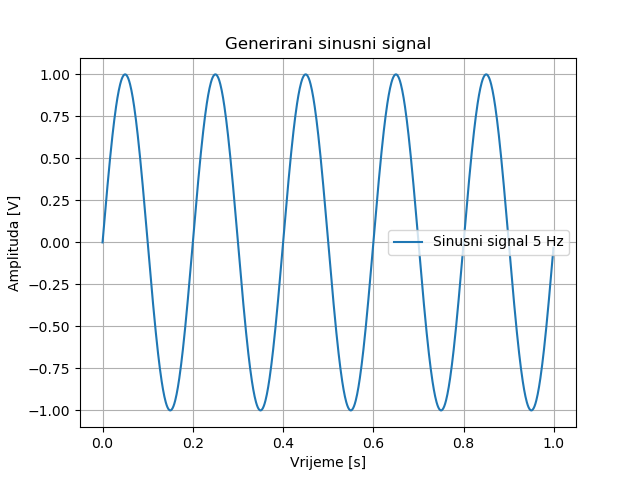

In [4]:
import numpy as np  # Učitaj biblioteku za numeričke operacije
import matplotlib.pyplot as plt  # Učitaj biblioteku za iscrtavanje

# 1. definiranje nezavisne varijable (Generiranje vremenske osi)
trajanje = 1.0  # Trajanje signala u sekundama
frekvencija_uzorkovanja = 1000  # Frekvencija uzorkovanja u Hz 
vrijeme = np.linspace(0, trajanje, int(frekvencija_uzorkovanja * trajanje), endpoint=False)

# 2. definiranje parametara signala
amplituda = 1.0  # Amplituda signala
frekvencija = 5  # Frekvencija sinusnog signala u Hz
pocetna_faza = 0 # Početna faza signala

# 3. generiranje sinusnog signala
sinusni_signal = amplituda * np.sin(2 * np.pi * frekvencija * vrijeme + pocetna_faza) 


# 4. prikaz generiranog signala
plt.figure()  
plt.plot(vrijeme, sinusni_signal, label=f'Sinusni signal {frekvencija} Hz')  # Crtanje signala
plt.xlabel('Vrijeme [s]')  # Oznaka x-osi
plt.ylabel('Amplituda [V]')  # Oznaka y-osi
plt.title('Generirani sinusni signal')  
plt.legend()  
plt.grid(True)  
plt.show()  


## Eulerova formula

U obradi signala sinusni i kosinusni signali imaju vrlo važnu ulogu jer se mnogi signali mogu predstaviti kao zbroj sinusnih komponenti različitih frekvencija. Takav prikaz omogućuje analizu složenih signala u frekvencijskoj domeni.

Zbog toga je korisno imati matematički zapis koji pojednostavljuje rad s takvim signalima. Upravo to omogućuje Eulerova formula, koja povezuje trigonometrijske funkcije (sinus i kosinus) i kompleksnu eksponencijalnu funkciju:

$e^{j\phi} = \cos(\phi) + j\sin(\phi)$

gdje je $\phi$ fazni kut izražen u radijanima.

Ako uzmemo i kompleksno konjugirani izraz $e^{-j\phi} = \cos(\phi) - j\sin(\phi)$
možemo dobiti izraze za kosinus i sinus pomoću eksponencijalnih funkcija:
$\cos(\phi)=\frac{e^{j\phi}+e^{-j\phi}}{2}$

$\sin(\phi)=\frac{e^{j\phi}-e^{-j\phi}}{2j}$

To znači da kosinus možemo promatrati kao srednju vrijednost dviju kompleksnih eksponencijalnih funkcija suprotnih faza, a da je sinus proporcionalan razlici dviju kompleksnih eksponencijalnih funkcija suprotnih faza. 

### Zašto je to važno?
Kompleksne eksponencijalne funkcije imaju jednostavna matematička svojstva. Deriviranje, integriranje i množenje svodi se na jednostavne algebarske operacije nad eksponentima pa su zbog toga te funkcije temelj mnogih metoda u obradi signala. Jedna od njih je __Fourierova transformacija__ kojom ćemo se baviti kasnije. 



## Diskretizacija i kvantizacija signala

__Kontinuirani signali__ definirani su za svaki trenutak u vremenu i mogu poprimiti bilo koju vrijednost unutar određenog raspona. Primjer takvog signala je analogni audio signal koji predstavlja zvučne valove kao neprekidnu funkciju vremena. U zapisu kontinuiranog signala koristimo oble zagrade: $x(t)$.

__Diskretni signali__, s druge strane, definirani su samo u određenim, diskretnim trenucima vremena. Vrijednosti između tih trenutaka nisu definirane. Primjer diskretnog signala je digitalni audio zapis gdje se uzimaju uzorci analognog signala u pravilnim intervalima, a svaki uzorak predstavlja vrijednost signala u tom trenutku. U zapisu diskretnog signala koristimo indeksni zapis s uglatim zagradama: $x[n]$ ($n$ predstavlja indeks uzorka, a ne vrijeme).

Prilikom pretvaranja analognog signala u digitalni oblik prolazimo kroz dva ključna procesa: diskretizaciju i kvantizaciju. Ova dva procesa omogućuju obradu signala na računalima i drugim digitalnim sustavima.

__Diskretizacija__ je proces uzorkovanja kontinuiranog signala u diskretnim vremenskim točkama. To znači da uzimamo uzorke signala u pravilnim vremenskim intervalima. 

Ako imamo kontinuirani signal $x(t)$, diskretizirani signal dobivamo uzorkovanjem s periodom uzorkovanja $T_s$:

$x[n]=x(nT_s)$,   $ n\in \mathbb{Z}$


gdje je $T_s$ period uzorkovanja (obrnuto proporcionalno od frekvencije uzorkovanja, odnosno $f_s=1/T_s$).

Prema __Nyquist-Shannonovom teoremu uzorkovanja__, frekvencija uzorkovanja mora biti barem dvostruko veća od najveće frekvencije u signalu kako bi se izbjegao aliasing (gubitak informacija zbog nedovoljno čestog uzorkovanja). Dakle, ako signal $x(t)$ sadrži samo frekvencije do $f_{max}$, tada frekvencija uzorkovanja mora biti:

$f_s\ge2f_{max}$

***

__Kvantizacija__ je proces zaokruživanja amplitudnih vrijednosti u diskretiziranim uzorcima signala na najbližu vrijednost iz ograničenog skupa mogućih vrijednosti (na najbližu kvantizacijsku razinu).  

Kvantizacija može biti:
- Uniformna – jednaki razmaci između razina kvantizacije,
- Neuniformna – različiti razmaci (češće se koristi u obradi govora).

Mjerilo kvalitete kvantizacije je kvantizacijska pogreška:
$e_q[n]=x[n]−x_q[n]$. 
Kvantizacijska pogreška ponaša se poput dodatnog kvantizacijskog šuma, koji može uzrokovati izobličenja signala.

Kombinacija diskretizacije i kvantizacije naziva se __analogno-digitalna pretvorba__ (A/D pretvorba).

<IPython.core.display.Javascript object>


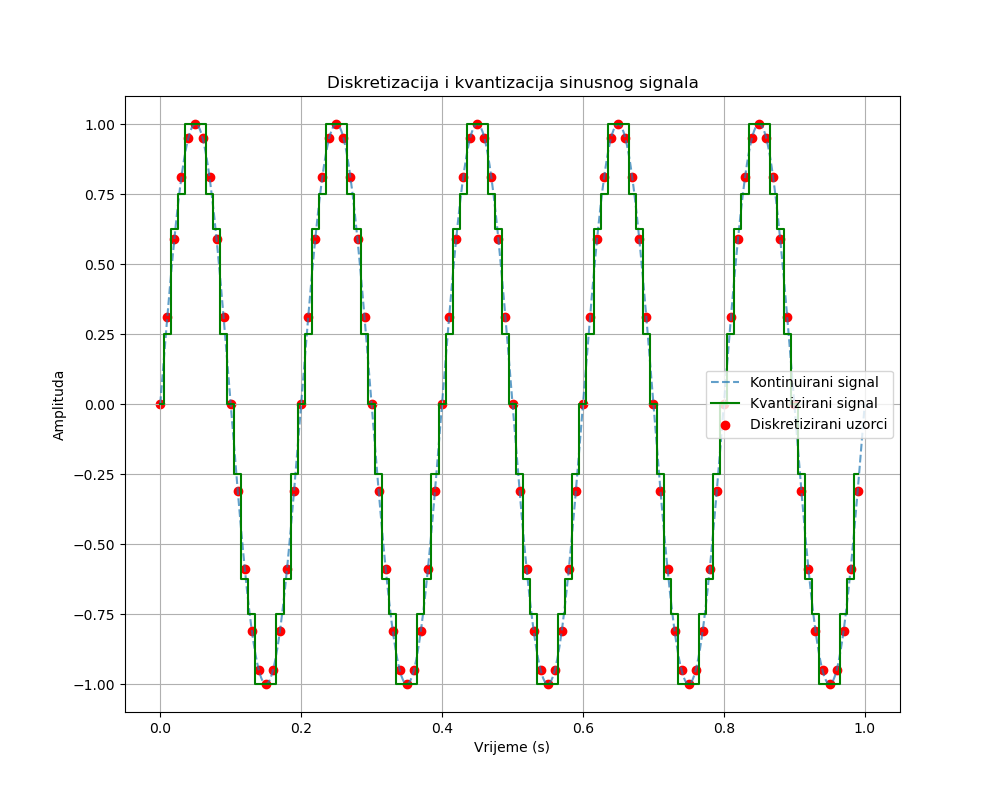

In [101]:
import numpy as np
import matplotlib.pyplot as plt

# Parametri za diskretizaciju i uzorkovanje
fs_disc = 100    # Frekvencija uzorkovanja (diskretizacija)
num_levels = 16 # Broj razina kvantizacije

# Generiranje kontinuiranog signala
fs_cont = 1000  # Signal izgleda kao kontinuirani (i dalje je samo niz točaka)
t_cont = np.linspace(0, 1, fs_cont)  # nezavisna varijabla
signal_cont = np.sin(2 * np.pi * 5 * t_cont)  # Sinusni signal od 5 Hz

# Diskretizacija signala
t_disc = np.arange(0, 1, 1/fs_disc)  # Diskretne vremenske točke
signal_disc = np.sin(2 * np.pi * 5 * t_disc)

# Kvantizacija signala
q_step = 2 / num_levels  # Veličina kvantizacijskog koraka (raspon -1 do 1)
signal_quant = np.round(signal_disc / q_step) * q_step  # Kvantizacija

# Grafički prikaz rezultata
plt.figure(figsize=(10,8))

# Prikaz kontinuiranog signala
plt.plot(t_cont, signal_cont, label="Kontinuirani signal", linestyle="dashed", alpha=0.7)

# Prikaz diskretiziranog signala
plt.scatter(t_disc, signal_disc, color="red", label="Diskretizirani uzorci")

# Prikaz kvantiziranog signala
plt.step(t_disc, signal_quant, where="mid", color="green", label="Kvantizirani signal")

plt.xlabel("Vrijeme (s)")
plt.ylabel("Amplituda")
plt.title("Diskretizacija i kvantizacija sinusnog signala")
plt.legend()
plt.grid()
plt.show()


## Operacije nad diskretnim signalima

Diskretni signali često se prikazuju kao stupčasti impulsi jer takav prikaz jasno pokazuje vrijednosti signala u pojedinim diskretnim trenucima $n$. Na takvim signalima mogu se jednostavno demonstrirati osnovne operacije koje se često koriste u obradi signala.


1. __Zrcaljenje__ (engl. Flipping)

Zrcaljenje signala obrće redoslijed uzoraka oko ishodišta $n=0$. Drugim riječima, uzorci koji su bili desno od nule premještaju se lijevo, i obrnuto:
$x[n] \rightarrow x[-n]$

Ako je signal imao vrijednost $x[3]$, nakon zrcaljenja ta vrijednost se pojavljuje u trenutku $n=-3$. Ova operacija je posebno važna kod izračuna konvolucije diskretnih signala, gdje se jedan od signala najprije zrcali, a zatim pomiče kroz drugi signal.

2. __Skaliranje__ (engl. Scaling)

Skaliranje mijenja vremensku skalu signala, odnosno razmak između uzoraka:

$x[n] \rightarrow x[k n]$

gdje je $k$ faktor skaliranja.

- Ako je $k>1$ signal se komprimira (sažima) u vremenu jer se uzorci efektivno približavaju. Dolazi do gubitka dijela informacija.

- Ako je $0<k<1$ signal se rasteže u vremenu jer se razmak između uzoraka povećava.


3. __Pomak__ (engl. Shifting)

Pomak signala znači pomicanje signala lijevo ili desno po osi indeksa $n$. Ova operacija se često koristi za modeliranje kašnjenja ili ubrzavanja signala:
$x[n] \rightarrow x[n-k]$

gdje je $k$ broj uzoraka za koji se signal pomiče.

- Ako je $k>0$ signal se pomiče udesno, što predstavlja kašnjenje signala.

- Ako je $k<0$ signal se pomiče ulijevo, što znači da se signal pojavljuje ranije.

Na primjer, ako je $x[n] \rightarrow x[n-2]$ signal se pomiče za dva uzorka udesno, odnosno svaki uzorak pojavljuje se dva koraka kasnije.

<img src="https://i.postimg.cc/2Sq05fyf/operacije-diskretni-1.png" />